In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
uploaded = files.upload()
IMAGES_DIR = '/content'

Saving 1.JPG to 1.JPG
Saving 2.jpg to 2.jpg
Saving 3.jpg to 3.jpg
Saving 4.jpg to 4.jpg
Saving 5.JPG to 5.JPG


In [5]:
IMAGES_DIR = '/content'
RESULT_DIR = '/content/result'
EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp')

os.makedirs(RESULT_DIR, exist_ok=True)


def load_frames(folder):
    """Читает все изображения из папки в словарь {метка_файла: массив}."""
    frames = {}
    for name in sorted(os.listdir(folder)):
        stem, ext = os.path.splitext(name)
        if ext.lower() not in EXTENSIONS:
            continue
        frame = cv2.imread(os.path.join(folder, name), cv2.IMREAD_COLOR)
        if frame is None:
            print(f"Файл {name} не читается — пропускаю")
            continue
        frames[stem] = frame
    return frames


def build_kernel(values):
    """Матрица свёртки + нормализация, если сумма не нулевая."""
    kernel = np.array(values, dtype=float)
    total = kernel.sum()
    return kernel / total if total != 0 else kernel


kernels = {
    'original': None,
    'low_pass': build_kernel([[1, 1, 1, 1, 1]] * 5),
    'grain': build_kernel([[0.0, -1.0, 0.0],
                           [-1.0, 4.0, -1.0],
                           [0.0, -1.0, 0.0]]),
    'color': build_kernel([[0.0, -1.0, 0.0],
                           [-1.0, 5.0, -1.0],
                           [0.0, -1.0, 0.0]]),
    'h_lines': build_kernel([[-1.0, -1.0],
                             [2.0, 2.0],
                             [-1.0, -1.0]]),
    'v_lines': build_kernel([[-1.0, 2.0, -1.0],
                             [-1.0, 2.0, -1.0]]),
}

shots = load_frames(IMAGES_DIR)
processed = {}

for tag, frame in shots.items():
    processed[tag] = {}
    for kind, kernel in kernels.items():
        if kernel is None:
            processed[tag][kind] = frame.copy()
        else:
            processed[tag][kind] = cv2.filter2D(frame, -1, kernel)
            cv2.imwrite(f'{RESULT_DIR}/{tag}_{kind}.jpg', processed[tag][kind])
    print(f'{tag}: сохранено {len(kernels) - 1} отфильтрованных копий')

1: сохранено 5 отфильтрованных копий
2: сохранено 5 отфильтрованных копий
3: сохранено 5 отфильтрованных копий
4: сохранено 5 отфильтрованных копий
5: сохранено 5 отфильтрованных копий


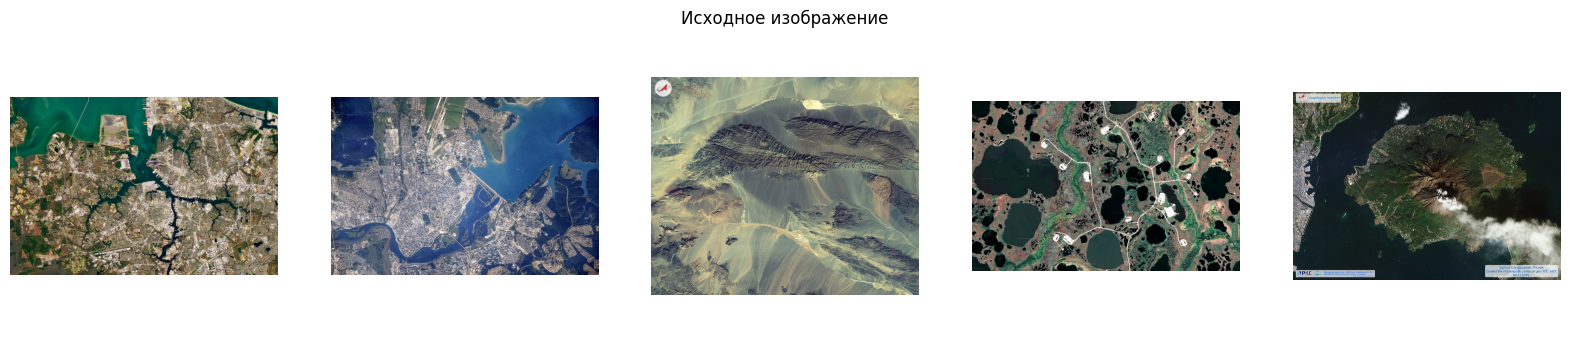

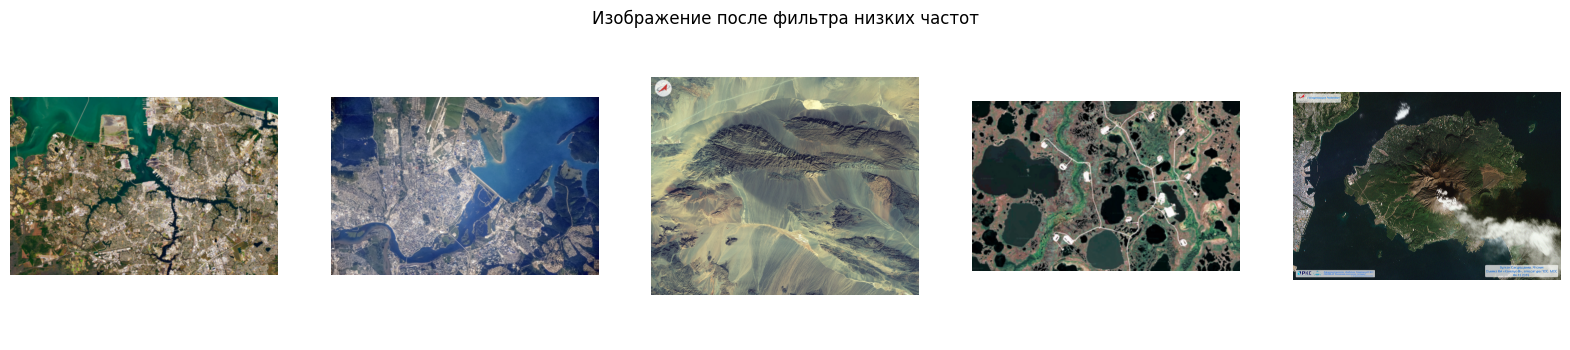

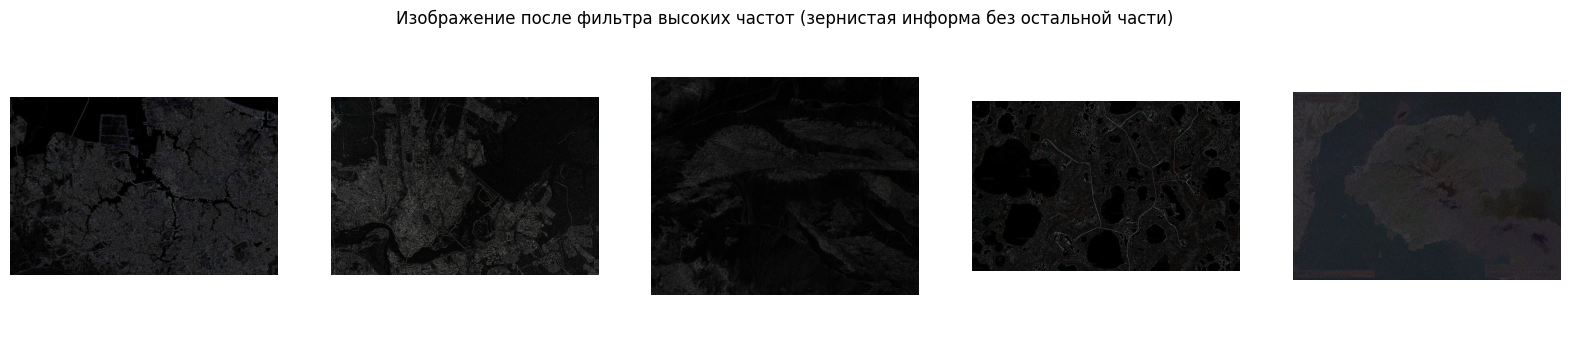

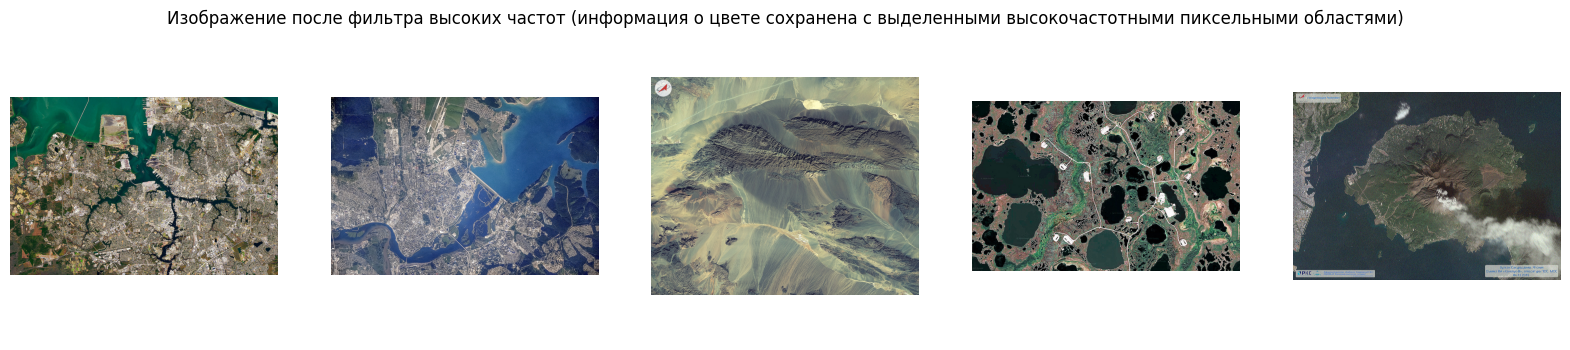

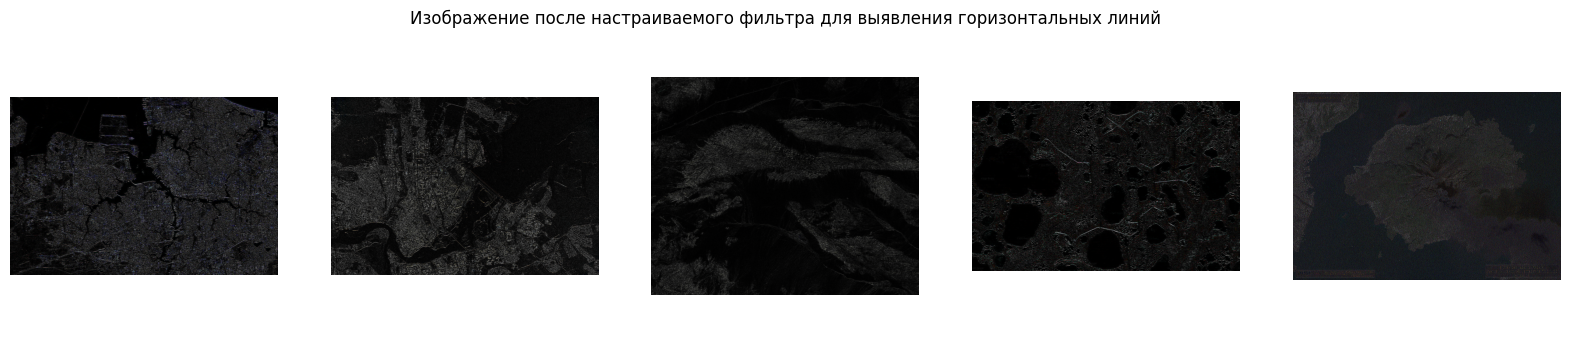

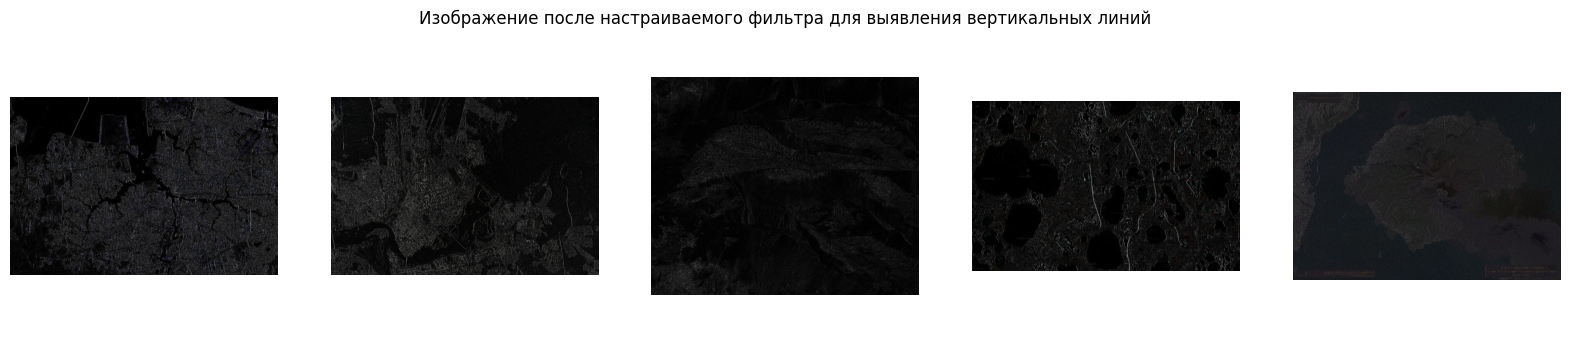

In [7]:
captions = {
    'original': 'Исходное изображение',
    'low_pass': 'Изображение после фильтра низких частот',
    'grain': ('Изображение после фильтра высоких частот '
              '(зернистая информа без остальной части)'),
    'color': ('Изображение после фильтра высоких частот '
              '(информация о цвете сохранена с выделенными '
              'высокочастотными пиксельными областями)'),
    'h_lines': 'Изображение после настраиваемого фильтра для выявления горизонтальных линий',
    'v_lines': 'Изображение после настраиваемого фильтра для выявления вертикальных линий',
}

for kind, caption in captions.items():
    plt.figure(figsize=(20, 4))
    plt.title(caption)
    plt.axis('off')
    for pos, tag in enumerate(shots, start=1):
        plt.subplot(1, len(shots), pos)
        plt.imshow(cv2.cvtColor(processed[tag][kind], cv2.COLOR_BGR2RGB))
        plt.axis('off')
    plt.show()

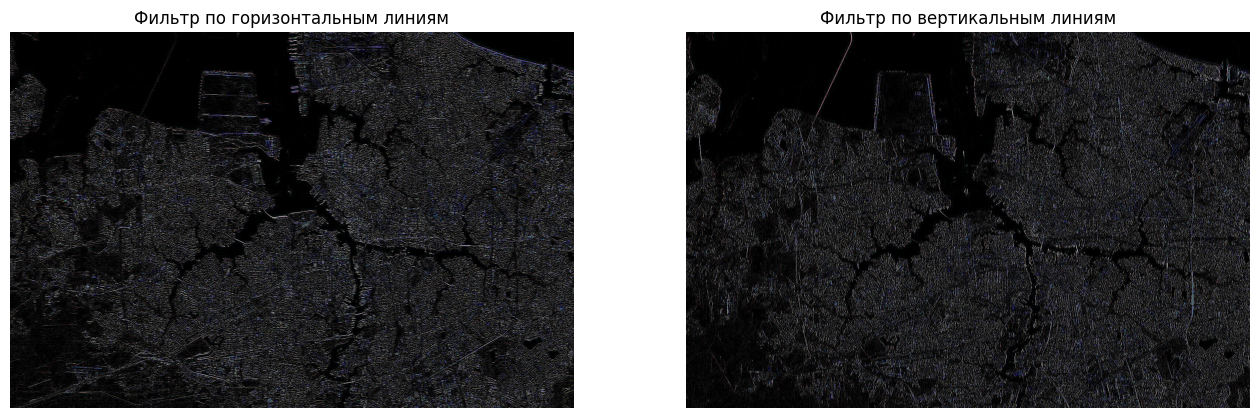

In [8]:
plt.figure(figsize=(16, 12))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(processed['1']['h_lines'], cv2.COLOR_BGR2RGB))
plt.title('Фильтр по горизонтальным линиям')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(processed['1']['v_lines'], cv2.COLOR_BGR2RGB))
plt.title('Фильтр по вертикальным линиям')
plt.axis('off')

plt.show()

Фильтр низких частот

Общий световой тон снимка почти не меняет. Пропадают мелкие детали и резкие переходы между соседними участками. На снимках города исчезает сетка улиц и отдельная застройка — они сливаются в светлые размытые пятна; на снимке вулкана смазывается шлейф и мелкая складчатость склонов. Хорошо читаются крупные однородные области: акватория, поля, лесные массивы, ровные контуры прудов-накопителей и взлётной полосы. Такие фильтры лучше применять, когда нужно убрать мелкую зернитость и шум и посмотреть на крупные объекты и границы — границу воды и суши, контуры лесных массивов, крупные геометрические сооружения.

Фильтр высоких частот

делает снимок почти чёрным, поэтомц остаётся только сама линия границы, а ровные участки гаснут. Это удобный способ посмотреть, где на съёмке вообще есть перепады. Ярче всего на таких картах выражены линейные объекты — береговая линия с изрезанными излучинами, русло реки и мосты, дороги и просеки, контур кратера и трещины на склонах, хорошо видны и границы участков с разной растительностью.

Ядро с центральным коэфф-ом 5:

не вырезает границы совсем, а усиливает их, поэтому цвет и общий тон сохраняются, но картинка становится перешумленной. На снимке горных складок проступает мелкая эрозийная сеть, которой на исходном почти не было видно, в городе становится различима квартальная сетка. Такую обработку стоит применять для детализации и выделения контуров, когда нужно разглядеть мелкие объекты — дорожную сеть, застройку, границы выделов, — то есть перед дешифрированием и поиском границ. Но вместе с деталями усиливается шум, поэтому на снимках с уже ровными участками (вода, болото) появляется заметная крупитистость.

Ориентированные ядра

Результат зависит от того, как расположены коэффициенты, а не только от их величин. Ядро, выделяющее горизонтальные линии, на всех пяти снимках дало более тёмную и бедную картинку, чем то же ядро, повёрнутое на 90°: вертикальных контуров — оврагов, дорог, береговых уступов, заходящих вверх русел — на этих съёмках явно больше, чем горизонтальных. Следовательно такие ядра удобно применять не ко всему снимку, а когда заранее известно направление интересующих объектов — например, искать протяжённые линейные объекты (дороги, ЛЭП, трубопроводы, складки) по их простиранию.

Чёрный фон на снимках после высокочастотных фильтров.

Ядро с нулевой суммой даёт и отрицательные значения, а пиксели хранятся беззнаковым типом, у которого ниже нуля ничего нет, — такие значения просто обрезаются в чёрный. Поэтому половина результата с минусом теряется, и по этой же причине фильтры с суммой ядра, равной нулю, не нормализуются.

Ядро diag_backslash, сумма коэффициентов = 0


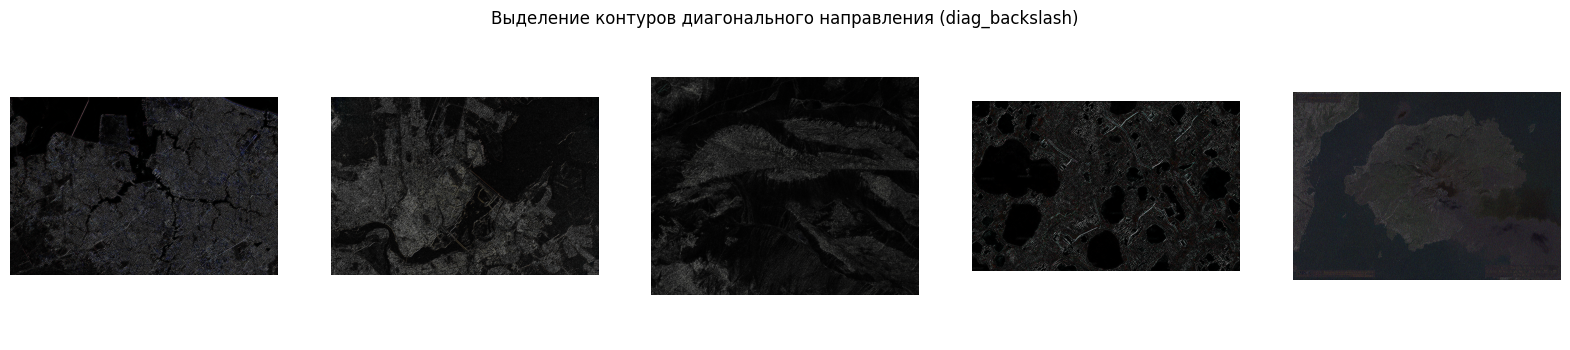

Ядро diag_slash, сумма коэффициентов = 0


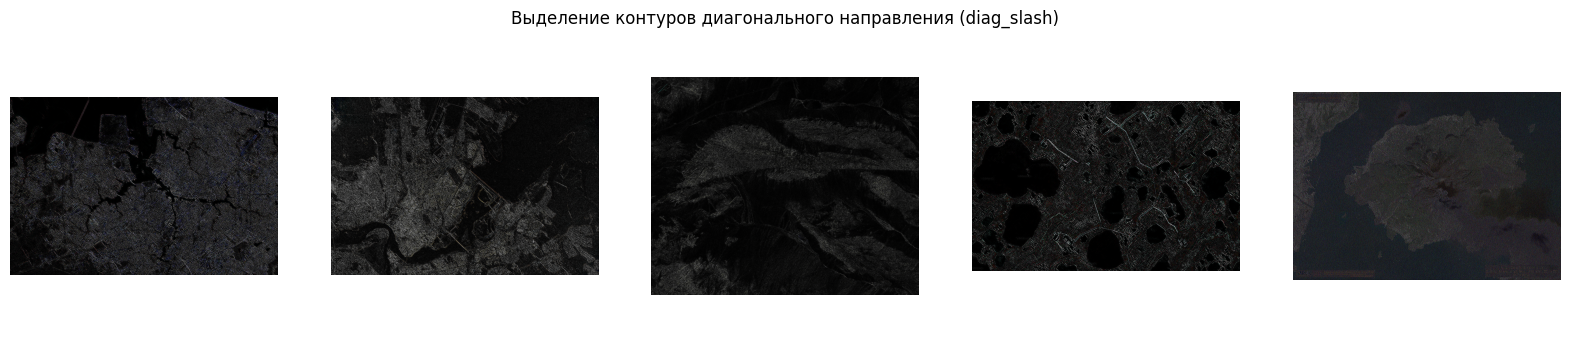

In [11]:
# выделяю контуры ток диагонального направления.
# Сумма кэфов равна нулю, поэтому яркость не смещается,
# остаются видимыми только перепады.
my_kernels = {
    'diag_backslash': np.array([[-1.0, -1.0, 2.0],
                                [-1.0,  2.0, -1.0],
                                [ 2.0, -1.0, -1.0]]),
    'diag_slash': np.array([[ 2.0, -1.0, -1.0],
                            [-1.0,  2.0, -1.0],
                            [-1.0, -1.0,  2.0]]),
}

for kind, kernel in my_kernels.items():
    print(f'Ядро {kind}, сумма коэффициентов = {kernel.sum():.0f}')
    for tag, frame in shots.items():
        result = cv2.filter2D(frame, -1, kernel)
        processed[tag][kind] = result
        cv2.imwrite(f'{RESULT_DIR}/{tag}_{kind}.jpg', result)

    plt.figure(figsize=(20, 4))
    plt.title(f'Выделение контуров диагонального направления ({kind})')
    plt.axis('off')
    for pos, tag in enumerate(shots, start=1):
        plt.subplot(1, len(shots), pos)
        plt.imshow(cv2.cvtColor(processed[tag][kind], cv2.COLOR_BGR2RGB))
        plt.axis('off')
    plt.show()

Где это применимо.

На снимках диагональных объектов больше всего на болотистой съёмке: просеки и кустовые дороги идут ломаными линиями под углом, русла мелких рек тоже; на городском снимке под углом уходят диагональные вылетные магистрали и участок набережной; на горном снимке косыми лежат оси складок и линии сбросов. Такое ядро полезно, когда нужно отсмотреть объекты, вытянутые под углом, не мешая себе горизонтальными и вертикальными контурами, которых на снимке всегда в разы больше: поиск косых трещин и сбросов, диагональных дорог и ЛЭП, границ вытянутых под углом вырубок или полей.